# IMDb Data Cleaning and Preprocessing

## Objective

The objective of this notebook is to clean and preprocess the extracted IMDb dataset for further exploratory data analysis (EDA). The cleaning process includes:

* handling duplicates,
* managing missing values,
* datatype validation,
* feature transformation,
* runtime conversion,
* vote count standardization,
* and preparing the final cleaned dataset.


In [8]:
import pandas as pd
import numpy as np

7. Read CSV File 
-  After exporting the data frame you need to import the data frame for 

- How many features(Columns) do you have?
- How many observations(rows) do you have?
- What is the data type of each feature(Columns)?
- How many missing values are there?


## Initial Dataset Inspection

Initial inspection was performed to:

* understand dataset structure,
* identify datatypes,
* detect missing values,
* and examine basic statistical summaries.


## Reading the Extracted Dataset

The extracted IMDb dataset was imported into pandas for cleaning and preprocessing.


In [9]:
df=pd.read_csv("FinalCsvMovie.csv")

In [10]:
df.head()

,Title,Year,Genre,Rating,Votes,Runtime,Certificate,Metascore
0,The Boys,2019,action,8.6,859K,NaN,TV-MA,NaN
1,Invincible,2021,action,8.7,331K,NaN,TV-MA,NaN
2,Street Fighter,2026,action,NaN,NaN,NaN,NaN,NaN
3,Balls Up,2026,action,4.6,6.8K,1h 44m,R,34.0
4,Daredevil: Born Again,2025,action,8.1,97K,NaN,TV-MA,NaN


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Title        4500 non-null   object 
 1   Year         4500 non-null   int64  
 2   Genre        4500 non-null   object 
 3   Rating       4005 non-null   float64
 4   Votes        4005 non-null   object 
 5   Runtime      1908 non-null   object 
 6   Certificate  3933 non-null   object 
 7   Metascore    1494 non-null   float64
dtypes: float64(2), int64(1), object(5)
memory usage: 281.4+ KB


## Statistical Summaries

In [14]:
df.describe(include="all")

# see this explanation later 
# Checl max for votes,runtime,certificate

,Title,Year,Genre,Rating,Votes,Runtime,Certificate,Metascore
count,4500,4500.00000,4500,4005.000000,4005,1908,3933,1494.000000
unique,255,NaN,10,NaN,191,62,8,NaN
top,One Piece,NaN,action,NaN,16K,1h 39m,TV-MA,NaN
freq,90,NaN,450,NaN,108,108,1431,NaN
mean,NaN,2020.12000,NaN,7.604045,NaN,NaN,NaN,63.120482
std,NaN,8.72528,NaN,1.087316,NaN,NaN,NaN,15.872151
min,NaN,1972.00000,NaN,4.500000,NaN,NaN,NaN,33.000000
25%,NaN,2018.00000,NaN,6.900000,NaN,NaN,NaN,53.000000
50%,NaN,2025.00000,NaN,7.800000,NaN,NaN,NaN,64.000000
75%,NaN,2026.00000,NaN,8.500000,NaN,NaN,NaN,73.000000


## DataType Identification

In [15]:
# Data type of columns
df.dtypes

Title           object
Year             int64
Genre           object
Rating         float64
Votes           object
Runtime         object
Certificate     object
Metascore      float64
dtype: object

## Checking For Missing Values

In [16]:
# Number of missing values present
df.isnull().sum()

Title             0
Year              0
Genre             0
Rating          495
Votes           495
Runtime        2592
Certificate     567
Metascore      3006
dtype: int64

## Checking For Duplicates 

In [17]:
df.duplicated().sum()

np.int64(4000)

In [18]:
df.duplicated(subset=["Title"]).sum()

np.int64(4245)

In [19]:
df["Title"].nunique()

255

In [20]:
df["Title"].value_counts().head(10)

Title
One Piece                                   90
Invincible                                  63
Daredevil: Born Again                       54
The Hunger Games: Sunrise on the Reaping    54
Star Wars: Maul - Shadow Lord               45
Avatar: Fire and Ash                        45
The Boys                                    45
Mercy                                       45
Jujutsu Kaisen                              45
Avatar: The Last Airbender                  45
Name: count, dtype: int64

# Data Cleaning 

In this section you have to clean the data like:   
- Removing the special characters,  
- Incorrect Headers, 
- Incorrect Format of the data (Invalid Values, Columns) 
- Converting the data types 
- Identifying and Treatment of the missing values,
- Identifying and treating the Outliers (Based on the Problem Statement or Data)  


In [21]:
df.head(10)

,Title,Year,Genre,Rating,Votes,Runtime,Certificate,Metascore
0,The Boys,2019,action,8.6,859K,NaN,TV-MA,NaN
1,Invincible,2021,action,8.7,331K,NaN,TV-MA,NaN
2,Street Fighter,2026,action,NaN,NaN,NaN,NaN,NaN
3,Balls Up,2026,action,4.6,6.8K,1h 44m,R,34.0
4,Daredevil: Born Again,2025,action,8.1,97K,NaN,TV-MA,NaN
5,Game of Thrones,2011,action,9.2,2.6M,NaN,TV-MA,NaN
6,The Madison,2026,action,7.9,15K,NaN,TV-MA,NaN
7,The Rookie,2018,action,8.0,126K,NaN,TV-14,NaN
8,Paradise,2025,action,7.9,77K,NaN,TV-MA,NaN
9,Star Wars: Maul - Shadow Lord,2026,action,8.5,6.4K,NaN,TV-PG,NaN


## Handling Duplicate Titles

Since the dataset was scraped genre-wise, the same title appeared multiple times across different genres.

To resolve this:

* records were grouped by title,
* genres were combined into lists,
* and numerical columns were aggregated appropriately.

This reduced duplicate entries while preserving multi-genre information.


In [23]:
# To check if Year, Rating, Runtime are simimlar across repeated rows
pd.set_option('display.max_rows', None)
df.groupby("Title")[["Year", "Rating", "Runtime"]].nunique()

,Year,Rating,Runtime
Title,,,
180,1,1,1
28 Years Later: The Bone Temple,1,1,1
3 Body Problem,1,1,0
56 Days,1,1,0
A Big Bold Beautiful Journey,1,1,1
A Knight of the Seven Kingdoms,1,1,0
Akira,1,1,1
Anaconda,1,1,1
Andor,1,1,0


**Observation**
- A duplicate consistency check was performed using groupby() and nunique(). 
- Almost all movies had a single unique value for year, rating, and runtime. 
- Only one movie showed multiple rating values, likely due to minor variations across IMDb listings. 
- As this affected only a single record, it was considered negligible and did not significantly impact the analysis.

In [24]:
result = df.groupby("Title")[["Year", "Rating", "Runtime"]].nunique()

result[(result > 1).any(axis=1)]

,Year,Rating,Runtime
Title,,,
Avatar: The Last Airbender,2,2,0
One Piece,2,2,0


In [25]:
# Grouping similar movie titles together 
df1 = df.groupby("Title").agg({
    "Genre": lambda x: list(set(x)),
    "Year": "first",
    "Rating": "first",
    "Votes": "first",
    "Runtime": "first",
    "Certificate": "first",
    "Metascore": "first"
}).reset_index()

**Observation**

After grouping duplicate titles:

* duplicate title entries were removed,
* genre information was preserved,
* and the dataset became suitable for further analysis.
* The raw scraped dataset contained duplicate movie-genre combinations.
* These duplicates likely arose from overlapping search results across pages and the appearance of the same title in multiple IMDb search rankings.
* To obtain a unique movie-level dataset, records were grouped by title and duplicate genre assignments were removed during the data-cleaning process.


In [26]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Title        255 non-null    object 
 1   Genre        255 non-null    object 
 2   Year         255 non-null    int64  
 3   Rating       233 non-null    float64
 4   Votes        233 non-null    object 
 5   Runtime      105 non-null    object 
 6   Certificate  225 non-null    object 
 7   Metascore    85 non-null     float64
dtypes: float64(2), int64(1), object(5)
memory usage: 16.1+ KB


In [27]:
df1.head()

,Title,Genre,Year,Rating,Votes,Runtime,Certificate,Metascore
0,180,"[crime, drama, thriller]",2026,4.5,1.3K,1h 34m,TV-MA,NaN
1,28 Years Later: The Bone Temple,"[sci-fi, thriller]",2026,7.3,88K,1h 49m,R,81.0
2,3 Body Problem,[fantasy],2024,7.5,180K,None,TV-MA,NaN
3,56 Days,[romance],2026,6.7,9.6K,None,TV-MA,NaN
4,A Big Bold Beautiful Journey,[romance],2025,6.0,21K,1h 49m,R,43.0


### Checking for duplicate values

In [28]:
df1["Title"].duplicated().sum()

np.int64(0)

## Inspecting Each Column

### Title column

In [32]:
df1["Title"].nunique()

255

In [33]:
df1["Title"].isnull().sum()

np.int64(0)

In [34]:
df1["Title"].dtype

dtype('O')

In [35]:
len(df1)

255

**Observations**
- The Title column contains 255 unique movie titles, indicating that the dataset consists of 255 distinct movies after grouping duplicate entries. - No missing values were observed, suggesting that movie identification information was completely captured during scraping.
- The column is stored as an object data type, which is suitable for textual data.
- Each row in the final dataset represents a unique movie title, with no duplicate titles remaining after the grouping process.

### Genre column

In [21]:
# df1["Genre"].nunique()

In [36]:
df1["Genre"].value_counts().sum()

np.int64(255)

In [23]:
df1["Genre"].isnull().sum()

np.int64(0)

In [24]:
df1["Genre"].dtype

dtype('O')

In [37]:
from collections import Counter

Counter(g for genres in df1["Genre"] for g in genres)

Counter({'crime': 50,
         'drama': 50,
         'thriller': 50,
         'sci-fi': 50,
         'romance': 50,
         'animation': 50,
         'action': 49,
         'adventure': 49,
         'comedy': 49,
         'fantasy': 48})

**Observation**

- The Genre column contains no missing values and is stored as an object data type.
- Genre information is available for all 255 movies.
-  The genre distribution is highly balanced, with most genres contributing approximately 50 movies each.
-  Crime, Drama, Thriller, Sci-Fi, Romance, and Animation each contain 50 movies, while Action, Adventure, Comedy, and Fantasy contain 48–49 movies.
-  This balanced distribution is expected because the dataset was created by scraping a similar number of movies from each selected genre category.
-  Additionally, some movies belong to multiple genres, resulting in overlap between genre classifications.
- The dataset was intentionally constructed by scraping approximately 50 movies from each chosen genre, leading to a near-uniform genre distribution.


### Year column

In [38]:
df1["Year"].nunique()

35

In [39]:
df1["Year"].value_counts().sum()

np.int64(255)

In [40]:
df1["Year"].isnull().sum()

np.int64(0)

In [41]:
df1["Year"].dtype

dtype('int64')

In [42]:
df1["Year"].min()

1972

In [43]:
df1["Year"].max()

2027

In [44]:
df1["Year"].value_counts().head()
# see for 2027 over here

Year
2026    81
2025    38
2023    16
2024    11
2019    11
Name: count, dtype: int64

**Observation**

- The Year column contains release-year information for all 255 movies, with no missing values.
- It is stored as an int64 data type and is treated as a discrete numerical variable.
- The dataset spans 35 unique years, ranging from 1972 to 2027, indicating coverage of both older and recent movie releases.
- The distribution is heavily concentrated toward recent years, with 2026 accounting for the highest number of movies (81), followed by 2025 (38).
- This suggests that the IMDb search results used for data collection are strongly biased toward contemporary and upcoming titles rather than older releases.
- A small number of titles are associated with future release years (up to 2027), reflecting upcoming projects listed on IMDb.

### Rating column

In [45]:
df1["Rating"].dtype

dtype('float64')

In [46]:
df1["Rating"].value_counts().sum()

np.int64(233)

In [47]:
(df1["Rating"]<0).value_counts()

Rating
False    255
Name: count, dtype: int64

In [48]:
(df1["Rating"]==0).value_counts()

Rating
False    255
Name: count, dtype: int64

In [49]:
df1["Rating"].describe()

count    233.000000
mean       7.601717
std        1.069038
min        4.500000
25%        6.900000
50%        7.800000
75%        8.500000
max        9.500000
Name: Rating, dtype: float64

In [50]:
df1["Rating"].isnull().sum()

np.int64(22)

In [51]:
len(df1["Rating"])

255

In [52]:
(df1["Rating"].isnull().sum()/len(df1["Rating"]))*100

np.float64(8.627450980392156)

In [53]:
df1[df1["Rating"].isnull()]

,Title,Genre,Year,Rating,Votes,Runtime,Certificate,Metascore
9,Animal Farm,[animation],2026,NaN,None,1h 36m,PG,40.0
15,Avengers: Doomsday,"[action, sci-fi, adventure]",2026,NaN,None,None,None,NaN
16,Backrooms,[sci-fi],2026,NaN,None,1h 45m,None,NaN
57,Focker-in-Law,[comedy],2026,NaN,None,None,None,NaN
76,Harry Potter,[fantasy],2026,NaN,None,None,None,NaN
97,Little House on the Prairie,[romance],2026,NaN,None,None,None,NaN
102,Man on Fire,[crime],2026,NaN,None,None,None,NaN
105,Masters of the Universe,"[sci-fi, fantasy, adventure]",2026,NaN,None,None,None,NaN
113,Mortal Kombat II,"[action, fantasy, sci-fi, adventure]",2026,NaN,None,1h 56m,R,NaN
163,Spaceballs: The New One,"[sci-fi, comedy]",2027,NaN,None,None,None,NaN


In [54]:
df1["Rating"].skew()

np.float64(-0.7772135516460342)

In [55]:
df1["Rating"].kurt()

np.float64(0.1329603500013894)

**Observations**
- The Rating column is a continuous numerical variable stored as float64.
- Ratings are available for 233 out of 255 movies, with 22 missing values (8.63%).
- No invalid ratings (negative or zero values) were observed.
- Ratings range from 4.5 to 9.5, with a mean of 7.60 and a median of 7.80, indicating that most movies in the dataset are generally well-rated.
- The distribution exhibits moderate negative skewness (-0.78), suggesting a greater concentration of higher-rated movies and relatively fewer low-rated titles.
- The kurtosis value (0.13) is close to zero, indicating that the distribution is approximately normal in shape without extreme tails or outliers.
- Missing ratings were retained as null values because imputing subjective user ratings could introduce bias, while removing the affected records would reduce the dataset size.

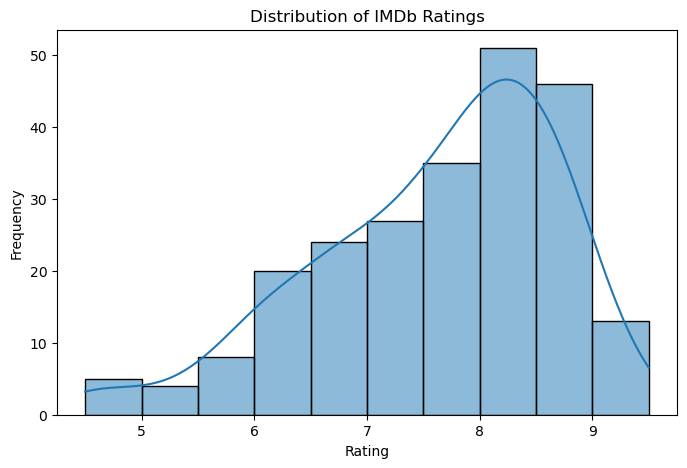

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
sns.histplot(df1["Rating"], bins=10, kde=True)
plt.title("Distribution of IMDb Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

### Votes column

In [59]:
df1.head()

,Title,Genre,Year,Rating,Votes,Runtime,Certificate,Metascore
0,180,"[crime, drama, thriller]",2026,4.5,1.3K,1h 34m,TV-MA,NaN
1,28 Years Later: The Bone Temple,"[sci-fi, thriller]",2026,7.3,88K,1h 49m,R,81.0
2,3 Body Problem,[fantasy],2024,7.5,180K,None,TV-MA,NaN
3,56 Days,[romance],2026,6.7,9.6K,None,TV-MA,NaN
4,A Big Bold Beautiful Journey,[romance],2025,6.0,21K,1h 49m,R,43.0


In [60]:
df1["Votes"].dtype

dtype('O')

In [61]:
df1["Votes"].isnull().sum()

np.int64(22)

In [62]:
len(df1["Votes"])

255

In [63]:
(df1["Votes"].isnull().sum()/len(df1["Votes"]))*100

np.float64(8.627450980392156)

In [64]:
df1[df1["Votes"].isnull()]

,Title,Genre,Year,Rating,Votes,Runtime,Certificate,Metascore
9,Animal Farm,[animation],2026,NaN,None,1h 36m,PG,40.0
15,Avengers: Doomsday,"[action, sci-fi, adventure]",2026,NaN,None,None,None,NaN
16,Backrooms,[sci-fi],2026,NaN,None,1h 45m,None,NaN
57,Focker-in-Law,[comedy],2026,NaN,None,None,None,NaN
76,Harry Potter,[fantasy],2026,NaN,None,None,None,NaN
97,Little House on the Prairie,[romance],2026,NaN,None,None,None,NaN
102,Man on Fire,[crime],2026,NaN,None,None,None,NaN
105,Masters of the Universe,"[sci-fi, fantasy, adventure]",2026,NaN,None,None,None,NaN
113,Mortal Kombat II,"[action, fantasy, sci-fi, adventure]",2026,NaN,None,1h 56m,R,NaN
163,Spaceballs: The New One,"[sci-fi, comedy]",2027,NaN,None,None,None,NaN


In [65]:
df1["Votes"].str[-1].value_counts()

Votes
K    213
M     15
8      2
2      1
5      1
3      1
Name: count, dtype: int64

#### Vote Count Standardization

IMDb vote counts were originally stored using:

* `K` for thousands,
* `M` for millions.

To simplify numerical analysis, all vote counts were converted into a unified numerical scale called `Votes_K`.


In [66]:
def convert_votes_k(v):
    if pd.isna(v):
        return None
    v=str(v)
    if v.endswith("M"):
        return float(v[:-1])*1000
    elif v.endswith("K"):
        return float(v[:-1])
    else:
        return float(v)/1000


In [67]:
df1["Votes_K"] = df1["Votes"].apply(convert_votes_k)

In [68]:
df1["Votes_K"]

0         1.300
1        88.000
2       180.000
3         9.600
4        21.000
5       235.000
6       226.000
7        58.000
8       274.000
9           NaN
10      442.000
11      711.000
12      159.000
13      440.000
14      610.000
15          NaN
16          NaN
17        0.562
18        6.800
19      167.000
20      831.000
21       17.000
22        6.800
23      736.000
24       27.000
25      232.000
26      102.000
27     2600.000
28      228.000
29      180.000
30        0.628
31      535.000
32      186.000
33       64.000
34       13.000
35        0.985
36      529.000
37       97.000
38      478.000
39      225.000
40       18.000
41      932.000
42      137.000
43       48.000
44        4.100
45      246.000
46       36.000
47       14.000
48       78.000
49       18.000
50       56.000
51      300.000
52       16.000
53        6.300
54      390.000
55      388.000
56      468.000
57          NaN
58       87.000
59     2500.000
60      308.000
61     1200.000
62      

In [69]:
df1["Votes_K"].describe()

count     233.000000
mean      312.402086
std       490.338114
min         0.562000
25%        23.000000
50%       128.000000
75%       390.000000
max      2800.000000
Name: Votes_K, dtype: float64

In [70]:
df1["Votes_K"].isnull().sum()

np.int64(22)

In [71]:
df1[df1["Votes_K"].isnull()]

,Title,Genre,Year,Rating,Votes,Runtime,Certificate,Metascore,Votes_K
9,Animal Farm,[animation],2026,NaN,None,1h 36m,PG,40.0,NaN
15,Avengers: Doomsday,"[action, sci-fi, adventure]",2026,NaN,None,None,None,NaN,NaN
16,Backrooms,[sci-fi],2026,NaN,None,1h 45m,None,NaN,NaN
57,Focker-in-Law,[comedy],2026,NaN,None,None,None,NaN,NaN
76,Harry Potter,[fantasy],2026,NaN,None,None,None,NaN,NaN
97,Little House on the Prairie,[romance],2026,NaN,None,None,None,NaN,NaN
102,Man on Fire,[crime],2026,NaN,None,None,None,NaN,NaN
105,Masters of the Universe,"[sci-fi, fantasy, adventure]",2026,NaN,None,None,None,NaN,NaN
113,Mortal Kombat II,"[action, fantasy, sci-fi, adventure]",2026,NaN,None,1h 56m,R,NaN,NaN
163,Spaceballs: The New One,"[sci-fi, comedy]",2027,NaN,None,None,None,NaN,NaN


In [72]:
df1=df1.drop(columns="Votes")

In [73]:
df1

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,"[crime, drama, thriller]",2026,4.5,1h 34m,TV-MA,NaN,1.300
1,28 Years Later: The Bone Temple,"[sci-fi, thriller]",2026,7.3,1h 49m,R,81.0,88.000
2,3 Body Problem,[fantasy],2024,7.5,None,TV-MA,NaN,180.000
3,56 Days,[romance],2026,6.7,None,TV-MA,NaN,9.600
4,A Big Bold Beautiful Journey,[romance],2025,6.0,1h 49m,R,43.0,21.000
5,A Knight of the Seven Kingdoms,"[action, fantasy, adventure, drama]",2026,8.7,None,TV-MA,NaN,235.000
6,Akira,[animation],1988,8.0,2h 4m,R,68.0,226.000
7,Anaconda,"[action, comedy, adventure]",2025,5.6,1h 39m,PG-13,43.0,58.000
8,Andor,[fantasy],2022,8.6,None,TV-14,NaN,274.000
9,Animal Farm,[animation],2026,NaN,1h 36m,PG,40.0,NaN


In [74]:
df1["Votes_K"].skew()

np.float64(2.989533534505966)

In [75]:
df1["Votes_K"].kurt()

np.float64(10.293281277865017)

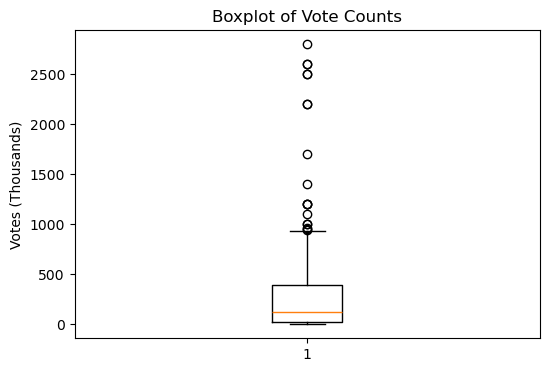

In [76]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.boxplot(df1["Votes_K"].dropna())
plt.title("Boxplot of Vote Counts")
plt.ylabel("Votes (Thousands)")
plt.show()

**Observation**

- The Votes_K column is a continuous numerical variable representing vote counts in thousands.
- The original vote counts were standardized from string-based formats containing K (thousand) and M (million) suffixes to facilitate quantitative analysis.
- The column contains 22 missing values (8.63%), which were retained because imputing vote counts would be unreliable and removing records would unnecessarily reduce the dataset size.
-  Vote counts vary substantially, ranging from 0.562K to 2800K votes.
-  The mean vote count (312.4K) is considerably higher than the median (128K), indicating a strongly right-skewed distribution.
-   This is confirmed by the skewness value of 2.99, which suggests that a small number of exceptionally popular movies receive disproportionately large numbers of votes.
-   Furthermore, the kurtosis value of 10.29 indicates heavy tails and the presence of extreme high-vote outliers, highlighting substantial variability in movie popularity across the dataset.

### Runtime column

In [77]:
df1["Runtime"].head()

0    1h 34m
1    1h 49m
2      None
3      None
4    1h 49m
Name: Runtime, dtype: object

In [78]:
df1["Runtime"].dtype

dtype('O')

In [79]:
df1["Runtime"].isnull().sum()

np.int64(150)

In [80]:
(df1["Runtime"].isnull().sum()/len(df1["Runtime"]))*100

np.float64(58.82352941176471)

In [57]:
# first convert format and then fill missing values acc to year and other cols 

#### Runtime Conversion

Runtime values were originally stored in string format such as:

* `1h 45m`
* `2h`
* `50m`

Regular expressions were used to extract hours and minutes separately and convert total runtime into minutes.


In [81]:
import re

In [82]:
def hour_to_min(x):
    if pd.isna(x):
        return None 
    hours=0
    minutes=0

    #Extract hours
    h=re.search(r'(\d+)\s*h',x)
    if h:
        hours=int(h.group(1))

    #Extract minutes
    m=re.search(r'(\d+)\s*m',x)
    if m:
        minutes=int(m.group(1))

    return hours*60+minutes

In [83]:
df1["Runtime"] = df1["Runtime"].apply(hour_to_min)

In [84]:
df1["Runtime"].isnull().sum()

np.int64(150)

**Observation**

- A significant number of runtime values were missing.
- Since runtime information could not be reliably inferred, missing values were retained as null values to avoid introducing inaccurate data into the dataset.


In [85]:
df1["Runtime"].head()

0     94.0
1    109.0
2      NaN
3      NaN
4    109.0
Name: Runtime, dtype: float64

In [86]:
df1["Runtime"].describe()

count    105.000000
mean     123.428571
std       28.841029
min       81.000000
25%      105.000000
50%      116.000000
75%      138.000000
max      235.000000
Name: Runtime, dtype: float64

In [87]:
df1["Runtime"].skew()

np.float64(1.3860324018473367)

In [88]:
df1["Runtime"].kurt()

np.float64(2.2515128576000274)

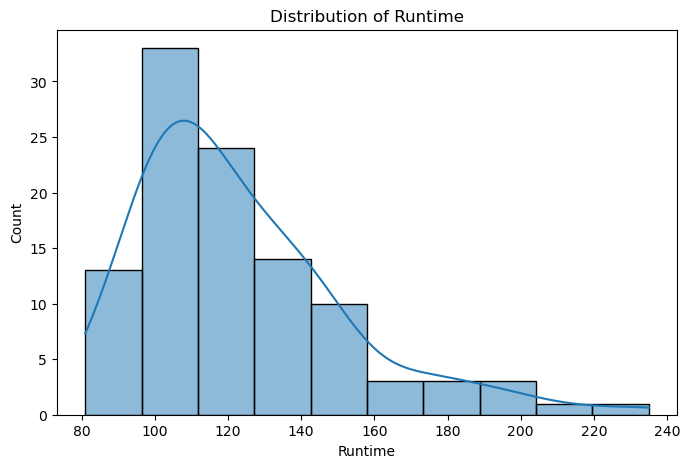

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
sns.histplot(df1["Runtime"], bins=10, kde=True)
plt.title("Distribution of Runtime")
plt.xlabel("Runtime")
plt.ylabel("Count")
plt.show()

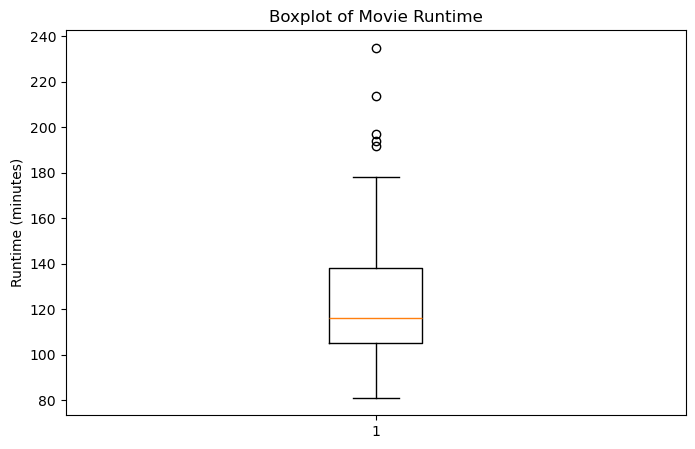

In [95]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.boxplot(df1["Runtime"].dropna())
plt.title("Boxplot of Movie Runtime")
plt.ylabel("Runtime (minutes)")
plt.show()

**Observation**
- The Runtime column originally contained duration values in text format and was converted into total minutes using regular expressions.
- The resulting variable is numerical and suitable for quantitative analysis.
-  However, 150 out of 255 records (58.82%) have missing runtime information, making this the column with the highest proportion of missing values in the dataset.
-  Since runtime values could not be reliably inferred, missing entries were retained as null values.
-  Among the available records, movie runtimes range from 81 to 235 minutes, with an average runtime of 123.43 minutes and a median runtime of 116 minutes.
- The distribution is positively skewed (skewness = 1.39), indicating that while most movies have moderate runtimes, a small number of significantly longer movies create a right tail.
- The kurtosis value of 2.25 further suggests the presence of extreme runtime values and heavier tails than a normal distribution.

### Certificate column

In [96]:
df1["Certificate"].value_counts()

Certificate
TV-MA       83
TV-14       41
R           40
PG-13       31
PG          16
TV-PG       11
G            2
TV-Y7-FV     1
Name: count, dtype: int64

In [97]:
df1["Certificate"].dtype

dtype('O')

In [98]:
df1["Certificate"].isnull().sum()

np.int64(30)

In [99]:
(df1["Certificate"].isnull().sum()/len(df1["Certificate"]))*100

np.float64(11.76470588235294)

In [100]:
df1[df1["Certificate"].isnull()]

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
15,Avengers: Doomsday,"[action, sci-fi, adventure]",2026,NaN,NaN,None,NaN,NaN
16,Backrooms,[sci-fi],2026,NaN,105.0,None,NaN,NaN
17,Ballistic,[thriller],2025,4.5,91.0,None,NaN,0.562
21,Bhooth Bangla,[comedy],2026,6.8,173.0,None,NaN,17.000
42,Dhurandhar,"[action, crime, adventure, thriller]",2025,8.3,214.0,None,NaN,137.000
43,Dhurandhar: The Revenge,"[action, crime, thriller]",2026,8.5,235.0,None,NaN,48.000
44,Do Deewane Seher Mein,[romance],2026,6.7,138.0,None,NaN,4.100
57,Focker-in-Law,[comedy],2026,NaN,NaN,None,NaN,NaN
76,Harry Potter,[fantasy],2026,NaN,NaN,None,NaN,NaN
97,Little House on the Prairie,[romance],2026,NaN,NaN,None,NaN,NaN


#### Handling Missing Certificate Values

Some titles did not contain certification information. Missing certificate values were replaced with `Unknown` to preserve rows while maintaining categorical consistency.


In [101]:
df1["Certificate"] = df1["Certificate"].fillna("Unknown")

In [102]:
df1[df1["Certificate"].isnull()]

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K


In [103]:
df1["Certificate"].isnull().sum()

np.int64(0)

In [104]:
df1["Certificate"].head()

0    TV-MA
1        R
2    TV-MA
3    TV-MA
4        R
Name: Certificate, dtype: object

**Observation**

- The Certificate column is a categorical variable stored as an object data type.
- Initially, 30 records (11.76%) had missing certification information.
- Rather than removing these records or assigning arbitrary values, missing entries were replaced with the category "Unknown" to preserve the dataset while maintaining categorical consistency.
- The most common certification was TV-MA (83 titles), followed by TV-14 (41 titles) and R (40 titles).
- The predominance of television-oriented certifications such as TV-MA, TV-14, and TV-PG suggests that the dataset contains a substantial number of TV series and streaming titles in addition to traditional feature films.
- Family-oriented certifications such as G and TV-Y7-FV were comparatively rare.

**Certificate	Meaning**

TV-MA - Mature Audience Only. Intended for adults (typically 17+). May contain strong language, violence, sexual content, or mature themes.

TV-14 -	Parents Strongly Cautioned. May be unsuitable for children under 14 due to language, violence, or suggestive content.

R -	Restricted. Viewers under 17 generally require a parent or guardian. May contain strong language, violence, nudity, or adult themes.

PG-13 -	Parents Strongly Cautioned. Some material may be inappropriate for children under 13.

PG - Parental Guidance Suggested. Some content may not be suitable for young children.

TV-PG - Parental Guidance Suggested for television content. Parents may want to supervise younger viewers.

G -	General Audiences. Suitable for all ages.

TV-Y7-FV -	Designed for children aged 7 and above. "FV" stands for Fantasy Violence, indicating cartoon or fantasy-style action.

Unknown	- Certification information was unavailable during scraping.


### Metascore column

In [105]:
df1[df1["Metascore"].isnull()]

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,"[crime, drama, thriller]",2026,4.5,94.0,TV-MA,NaN,1.300
2,3 Body Problem,[fantasy],2024,7.5,NaN,TV-MA,NaN,180.000
3,56 Days,[romance],2026,6.7,NaN,TV-MA,NaN,9.600
5,A Knight of the Seven Kingdoms,"[action, fantasy, adventure, drama]",2026,8.7,NaN,TV-MA,NaN,235.000
8,Andor,[fantasy],2022,8.6,NaN,TV-14,NaN,274.000
10,Arcane,[animation],2021,9.0,NaN,TV-14,NaN,442.000
11,Attack on Titan,"[action, fantasy, adventure, animation]",2013,9.1,NaN,TV-MA,NaN,711.000
13,Avatar: The Last Airbender,"[action, fantasy, adventure, animation]",2005,9.3,NaN,TV-Y7-FV,NaN,440.000
15,Avengers: Doomsday,"[action, sci-fi, adventure]",2026,NaN,NaN,Unknown,NaN,NaN
16,Backrooms,[sci-fi],2026,NaN,105.0,Unknown,NaN,NaN


In [106]:
df1["Metascore"].value_counts()

Metascore
68.0     5
73.0     5
61.0     3
58.0     3
71.0     3
64.0     3
49.0     3
66.0     3
78.0     3
44.0     2
34.0     2
43.0     2
46.0     2
80.0     2
53.0     2
55.0     2
37.0     2
75.0     2
65.0     2
74.0     2
84.0     2
50.0     2
62.0     2
59.0     2
77.0     2
85.0     2
96.0     2
81.0     1
40.0     1
82.0     1
72.0     1
67.0     1
60.0     1
95.0     1
70.0     1
39.0     1
33.0     1
87.0     1
86.0     1
57.0     1
100.0    1
92.0     1
56.0     1
48.0     1
54.0     1
Name: count, dtype: int64

In [107]:
df1["Metascore"].dtype

dtype('float64')

In [108]:
df1["Metascore"].isnull().sum()

np.int64(170)

In [109]:
df1["Metascore"].describe()

count     85.000000
mean      64.741176
std       15.767774
min       33.000000
25%       54.000000
50%       66.000000
75%       75.000000
max      100.000000
Name: Metascore, dtype: float64

In [110]:
df1["Metascore"].skew()

np.float64(-0.027163599053322444)

In [111]:
df1["Metascore"].kurt()

np.float64(-0.48529797260327845)

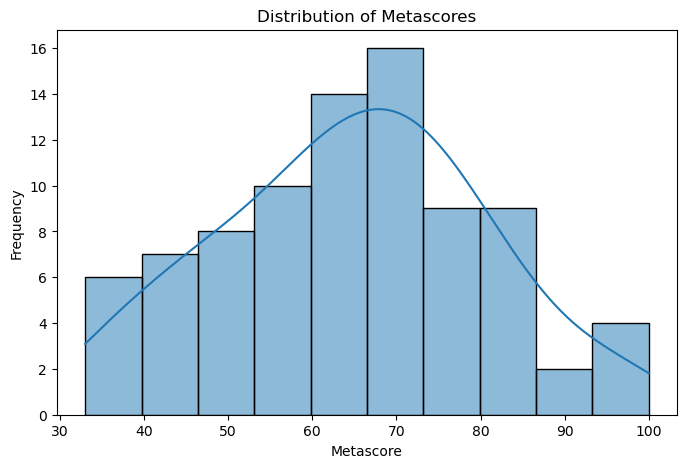

In [112]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sns.histplot(df1["Metascore"], bins=10, kde=True)
plt.title("Distribution of Metascores")
plt.xlabel("Metascore")
plt.ylabel("Frequency")
plt.show()

**Observation**

- The Metascore column is a continuous numerical variable stored as a float64 data type.
- A substantial proportion of values are missing, with 170 out of 255 records (66.67%) lacking Metascore information.
- This is likely because many titles had not received sufficient critic reviews or did not have official Metacritic ratings available.
- Since imputing critic scores could introduce bias and reduce data reliability, missing values were retained as null entries.
- Among the available records, Metascores range from 33 to 100, with an average score of 64.74 and a median score of 66.
- The distribution is nearly symmetric (skewness = -0.03), indicating a balanced spread of lower and higher scores.
- Additionally, the kurtosis value (-0.49) suggests a slightly flatter distribution than a normal distribution, with no evidence of extreme tails or unusually concentrated values.


In [75]:
# https://docs.google.com/document/d/1PZXgO3h7MEfy12LV_trB_sni-A9KMEHB2r8DLuVYTUU/edit?tab=t.0

## Outlier Detection

In [113]:
df1.describe()

,Year,Rating,Runtime,Metascore,Votes_K
count,255.000000,233.000000,105.000000,85.000000,233.000000
mean,2019.003922,7.601717,123.428571,64.741176,312.402086
std,9.698404,1.069038,28.841029,15.767774,490.338114
min,1972.000000,4.500000,81.000000,33.000000,0.562000
25%,2014.500000,6.900000,105.000000,54.000000,23.000000
50%,2024.000000,7.800000,116.000000,66.000000,128.000000
75%,2026.000000,8.500000,138.000000,75.000000,390.000000
max,2027.000000,9.500000,235.000000,100.000000,2800.000000


In [115]:
for col in numerical_cols:
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df1[(df1[col] < lower) | (df1[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

Rating: 3 outliers
Runtime: 5 outliers
Metascore: 0 outliers
Votes_K: 18 outliers


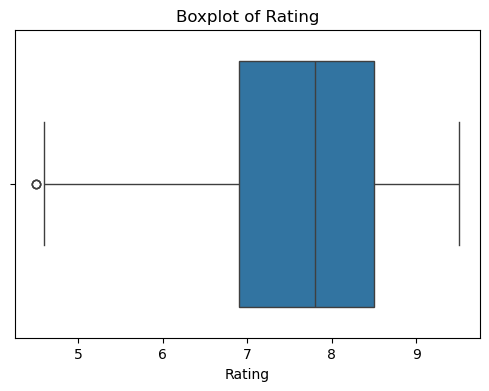

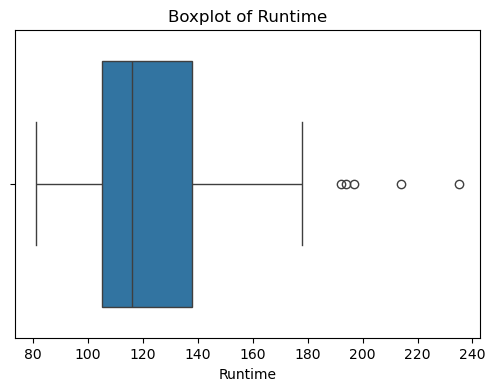

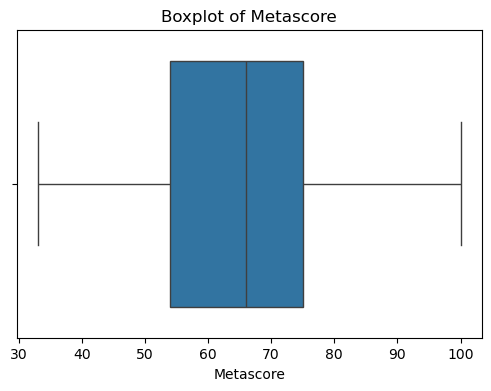

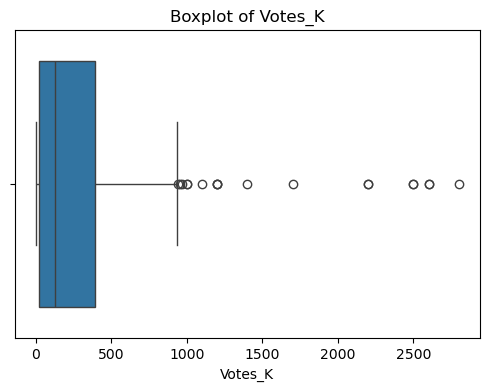

In [116]:
import seaborn as sns
import matplotlib.pyplot as plt
for col in ["Rating", "Runtime", "Metascore", "Votes_K"]:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df1[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

**Rating (3 outliers)**

- Since ratings are bounded between roughly 1 and 10, it's uncommon to have many outliers.
- The Rating column contains only 3 outliers based on the IQR method.
- Given the limited range of IMDb ratings and the small number of outliers, the rating distribution is relatively stable with few extreme observations.

**Runtime (5 outliers)**

- Positive skewness = 1.39
- Kurtosis = 2.25
- The Runtime column contains 5 outliers, corresponding to movies with unusually long durations compared to the majority of titles.
- These observations are consistent with the positive skewness of the runtime distribution and likely represent extended feature films rather than data-quality issues.

**Metascore (0 outliers)**

- Skewness ≈ 0
- Kurtosis ≈ -0.49
- No outliers were detected in the Metascore column using the IQR method.
- This indicates that critic scores are relatively well distributed across the observed range without extreme values.

**Votes_K (18 outliers)**

- Skewness = 2.99
- Kurtosis = 10.29
- Both values strongly indicate extreme high-end values.
- The Votes_K column contains 18 outliers, the highest among all numerical variables.
- These outliers correspond to exceptionally popular movies that have accumulated substantially more votes than the majority of titles.
- The presence of these outliers is consistent with the strong positive skewness and high kurtosis observed in the vote count distribution.

**Overall Outlier Conclusion**

- Outlier detection was performed using the Interquartile Range (IQR) method.
- Outliers were identified in the Rating (3), Runtime (5), and Votes_K (18) columns, while no outliers were found in the Metascore column.
- The highest number of outliers occurred in the Votes_K variable, reflecting a small number of exceptionally popular movies with very large vote counts.
- Since these outliers represent genuine movie characteristics rather than data-entry errors, they were retained for subsequent analysis.

## Clean Dataset

In [117]:
df1

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,"[crime, drama, thriller]",2026,4.5,94.0,TV-MA,NaN,1.300
1,28 Years Later: The Bone Temple,"[sci-fi, thriller]",2026,7.3,109.0,R,81.0,88.000
2,3 Body Problem,[fantasy],2024,7.5,NaN,TV-MA,NaN,180.000
3,56 Days,[romance],2026,6.7,NaN,TV-MA,NaN,9.600
4,A Big Bold Beautiful Journey,[romance],2025,6.0,109.0,R,43.0,21.000
5,A Knight of the Seven Kingdoms,"[action, fantasy, adventure, drama]",2026,8.7,NaN,TV-MA,NaN,235.000
6,Akira,[animation],1988,8.0,124.0,R,68.0,226.000
7,Anaconda,"[action, comedy, adventure]",2025,5.6,99.0,PG-13,43.0,58.000
8,Andor,[fantasy],2022,8.6,NaN,TV-14,NaN,274.000
9,Animal Farm,[animation],2026,NaN,96.0,PG,40.0,NaN


#### Exporting the Cleaned Dataset

After completing preprocessing and cleaning operations, the final cleaned dataset was exported as a CSV file for exploratory data analysis and visualization.


In [78]:
df1.to_csv("clean_dataset_final.csv", index=False)

# Conclusion

The dataset was successfully cleaned and transformed for further exploratory data analysis.

Major preprocessing tasks included:

* duplicate handling,
* missing value management,
* datatype validation,
* runtime conversion,
* vote count standardization,
* and preservation of multi-genre information.

The cleaned dataset is now suitable for univariate and bivariate analysis.


In [118]:
# https://docs.google.com/spreadsheets/d/1kCaSddGMQpI2Q-1UV8WU-VqPd5dgut7Szn2nPFkbhdI/edit?gid=0#gid=0
# https://docs.google.com/document/d/1PZXgO3h7MEfy12LV_trB_sni-A9KMEHB2r8DLuVYTUU/edit?tab=t.0